# Scratch: Phase 1 perception in a new scene, with a phone camera (exploratory)

## Section 1 - Purpose and expectations

This is an exploratory test, outside any study. It runs the perception of Phase 1, unchanged, on frames of a new scene: a room outside the laboratory, recorded with a phone instead of the headset. Nothing is measured, since the frames are not annotated, and nothing in Phase 1 changes. The aim is to see what to expect when the method leaves the laboratory.

Nine clips of about 10 s were recorded at 1080p or 4K and 30 fps, without HDR, with the phone held at eye level and pointed at the table. They form three series at three distances, close, middle and far, and each series has the same three contents: loose pieces on the table, a piece held in a bare hand, and a partly assembled figure. In the far series the pieces are about as large as in the headset videos; in the close series they are two to three times larger. The figure lies on its side in all three series, a pose not in the support set.

From each clip the frame at 5 s (frame 150) is taken, fixed before looking at any prediction. It is cropped to its central square and resized to 1024x1024, the size of the headset frames.

Expectations, written before the run, from the known limits of the method. Objects never seen in the laboratory are partly taken for pieces, since all background prototypes come from the laboratory and there is no "unknown" answer: dark objects such as the mouse pad, the keyboard and the mouse as hat or hand; red and pink objects as mouth, ear or nose; the bottle, the mug and the books as some piece. The pieces are recognized best in the far series, where their size is closest to the support set. The figure lying on its side is recognized worse than an upright one. The bare hands are recognized as hand.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 1:

Phase 1 test (phase_1_test.ipynb), Section 9: the known limits of the method, among them objects never seen.

scratch_working_distance.ipynb: pieces are recognized best at the scale of use.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 2 - Configuration

In [ ]:
# 2.1 Imports, paths, shared module and settings
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
CLIPS_DIR = PROJECT_ROOT / "data" / "raw_videos" / "iphone_scene"
PROTOTYPES_PATH = PROJECT_ROOT / "outputs" / "phase_1_perception" / "patch_prototypes.npz"   # saved by the pipeline, read only
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "scratch" / "iphone_scene"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for name, path in {"MODEL_DIR": MODEL_DIR, "CLIPS_DIR": CLIPS_DIR, "PROTOTYPES_PATH": PROTOTYPES_PATH}.items():
    print(f"[{'OK' if path.exists() else 'MISSING'}] {name}: {path}")

from perception.classes import CLASS_NAMES, BACKGROUND_LABEL, CLASS_COLORS
from perception.features import FeatureExtractor
from perception.prototypes import load_patch_prototypes, sort_by_class, class_similarities_gpu, assign_labels
from perception.visualization import render_overlay

DEVICE, DTYPE = "cuda", torch.bfloat16
MARGIN = 0.0                    # background margin of V2, as in the pipeline
MIN_BLOB_PATCHES = 5            # smallest blob that gets a text label in the overlays, as in the pipeline
SIZE = 1024                     # side of the headset frames
FRAME_INDEX = 150               # frame at 5 s of each clip, fixed before looking

CONTENTS = ["loose pieces", "piece in hand", "partly assembled"]
CLIPS = {"close": ["IMG_6799", "IMG_6801", "IMG_6802"],
         "middle": ["IMG_6803", "IMG_6804", "IMG_6805"],
         "far": ["IMG_6806", "IMG_6807", "IMG_6808"]}

[OK] MODEL_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\models\c_radio_weights
[OK] CLIPS_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\raw_videos\iphone_scene
[OK] PROTOTYPES_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_perception\patch_prototypes.npz


In [2]:
# 2.2 Frame at 5 s of each clip: central square, resized to 1024x1024, saved as png (no phone metadata)
FRAMES_DIR = OUTPUT_DIR / "frames"
FRAMES_DIR.mkdir(exist_ok=True)
FRAMES, rows = [], []
for distance, clips in CLIPS.items():
    for content, clip in zip(CONTENTS, clips):
        cap = cv2.VideoCapture(str(CLIPS_DIR / f"{clip}.MOV"))
        fps, width, height = cap.get(cv2.CAP_PROP_FPS), int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_INDEX)
        ok, frame_bgr = cap.read()
        cap.release()
        assert ok, f"Cannot read frame {FRAME_INDEX} of {clip}"
        h, w = frame_bgr.shape[:2]
        side = min(h, w)
        top, left = (h - side) // 2, (w - side) // 2
        square = cv2.cvtColor(frame_bgr[top:top + side, left:left + side], cv2.COLOR_BGR2RGB)
        image = Image.fromarray(square).resize((SIZE, SIZE), Image.Resampling.LANCZOS)
        path = FRAMES_DIR / f"{clip}_f{FRAME_INDEX:04d}.png"
        image.save(path)
        FRAMES.append({"clip": clip, "distance": distance, "content": content, "path": path, "image": image})
        rows.append({"clip": clip, "distance": distance, "content": content, "original size": f"{width}x{height}", "fps": round(fps, 2)})
display(pd.DataFrame(rows).set_index("clip"))

,distance,content,original size,fps
clip,,,,
IMG_6799,close,loose pieces,1920x1080,30.0
IMG_6801,close,piece in hand,1920x1080,30.0
IMG_6802,close,partly assembled,1920x1080,30.0
IMG_6803,middle,loose pieces,3840x2160,30.0
IMG_6804,middle,piece in hand,3840x2160,30.0
IMG_6805,middle,partly assembled,3840x2160,30.0
IMG_6806,far,loose pieces,1920x1080,30.0
IMG_6807,far,piece in hand,1920x1080,30.0
IMG_6808,far,partly assembled,1920x1080,30.0


Observation 2.2: The nine clips are read at 30 fps, six at 1920x1080 and the three of the middle series at 3840x2160. The frame at 5 s of each one is cropped to its central square and resized to 1024x1024.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 2: none. The settings are those of the pipeline (phase_1_perception.ipynb, Section 2.5).

------------------------------------------------------------------------------------------------------------------------------------------

## Section 3 - Predictions

The prototypes are those saved by the pipeline, loaded unchanged, as in the test of Phase 1 (Section 6). Each patch takes the class of its most similar prototype, with background margin 0.

In [3]:
# 3.1 Prototypes of the pipeline, model, and labels of the nine frames
saved = load_patch_prototypes(PROTOTYPES_PATH)
assert saved["class_names"] == CLASS_NAMES and saved["metadata"]["margin"] == MARGIN
PROTOTYPES_GPU = tuple(torch.as_tensor(a, device=DEVICE) for a in sort_by_class(saved["prototypes"], saved["owners"]))
extractor = FeatureExtractor(MODEL_DIR, device=DEVICE, dtype=DTYPE)

for item in FRAMES:
    features, resized = extractor.extract(item["image"])
    assert tuple(resized) == (SIZE, SIZE)
    item["labels"] = assign_labels(class_similarities_gpu(features, *PROTOTYPES_GPU), MARGIN)

np.savez_compressed(OUTPUT_DIR / "labels.npz", class_names=np.array(CLASS_NAMES),
                    **{item["clip"]: item["labels"].astype(np.uint8) for item in FRAMES})
counts = pd.DataFrame({item["clip"]: np.bincount(item["labels"].ravel(), minlength=len(CLASS_NAMES)) for item in FRAMES},
                      index=CLASS_NAMES).T
counts.insert(0, "distance", [item["distance"] for item in FRAMES])
counts.insert(1, "content", [item["content"] for item in FRAMES])
print("Patches of each class in each frame (64 x 64 = 4096 per frame):")
display(counts)

Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

Patches of each class in each frame (64 x 64 = 4096 per frame):


,distance,content,background,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2,hand
IMG_6799,close,loose pieces,3665,17,9,213,0,54,10,0,0,126,2,0
IMG_6801,close,piece in hand,3435,22,12,223,0,70,7,0,0,99,2,226
IMG_6802,close,partly assembled,2736,475,462,76,0,119,45,0,19,160,4,0
IMG_6803,middle,loose pieces,3651,29,113,111,18,56,23,32,16,44,3,0
IMG_6804,middle,piece in hand,3540,21,211,15,17,44,6,20,15,37,1,169
IMG_6805,middle,partly assembled,3554,193,145,34,29,63,3,10,36,28,1,0
IMG_6806,far,loose pieces,3797,7,52,70,9,52,32,27,13,37,0,0
IMG_6807,far,piece in hand,3367,18,85,54,10,50,26,26,21,9,0,430
IMG_6808,far,partly assembled,3559,186,134,6,38,85,2,13,19,39,15,0


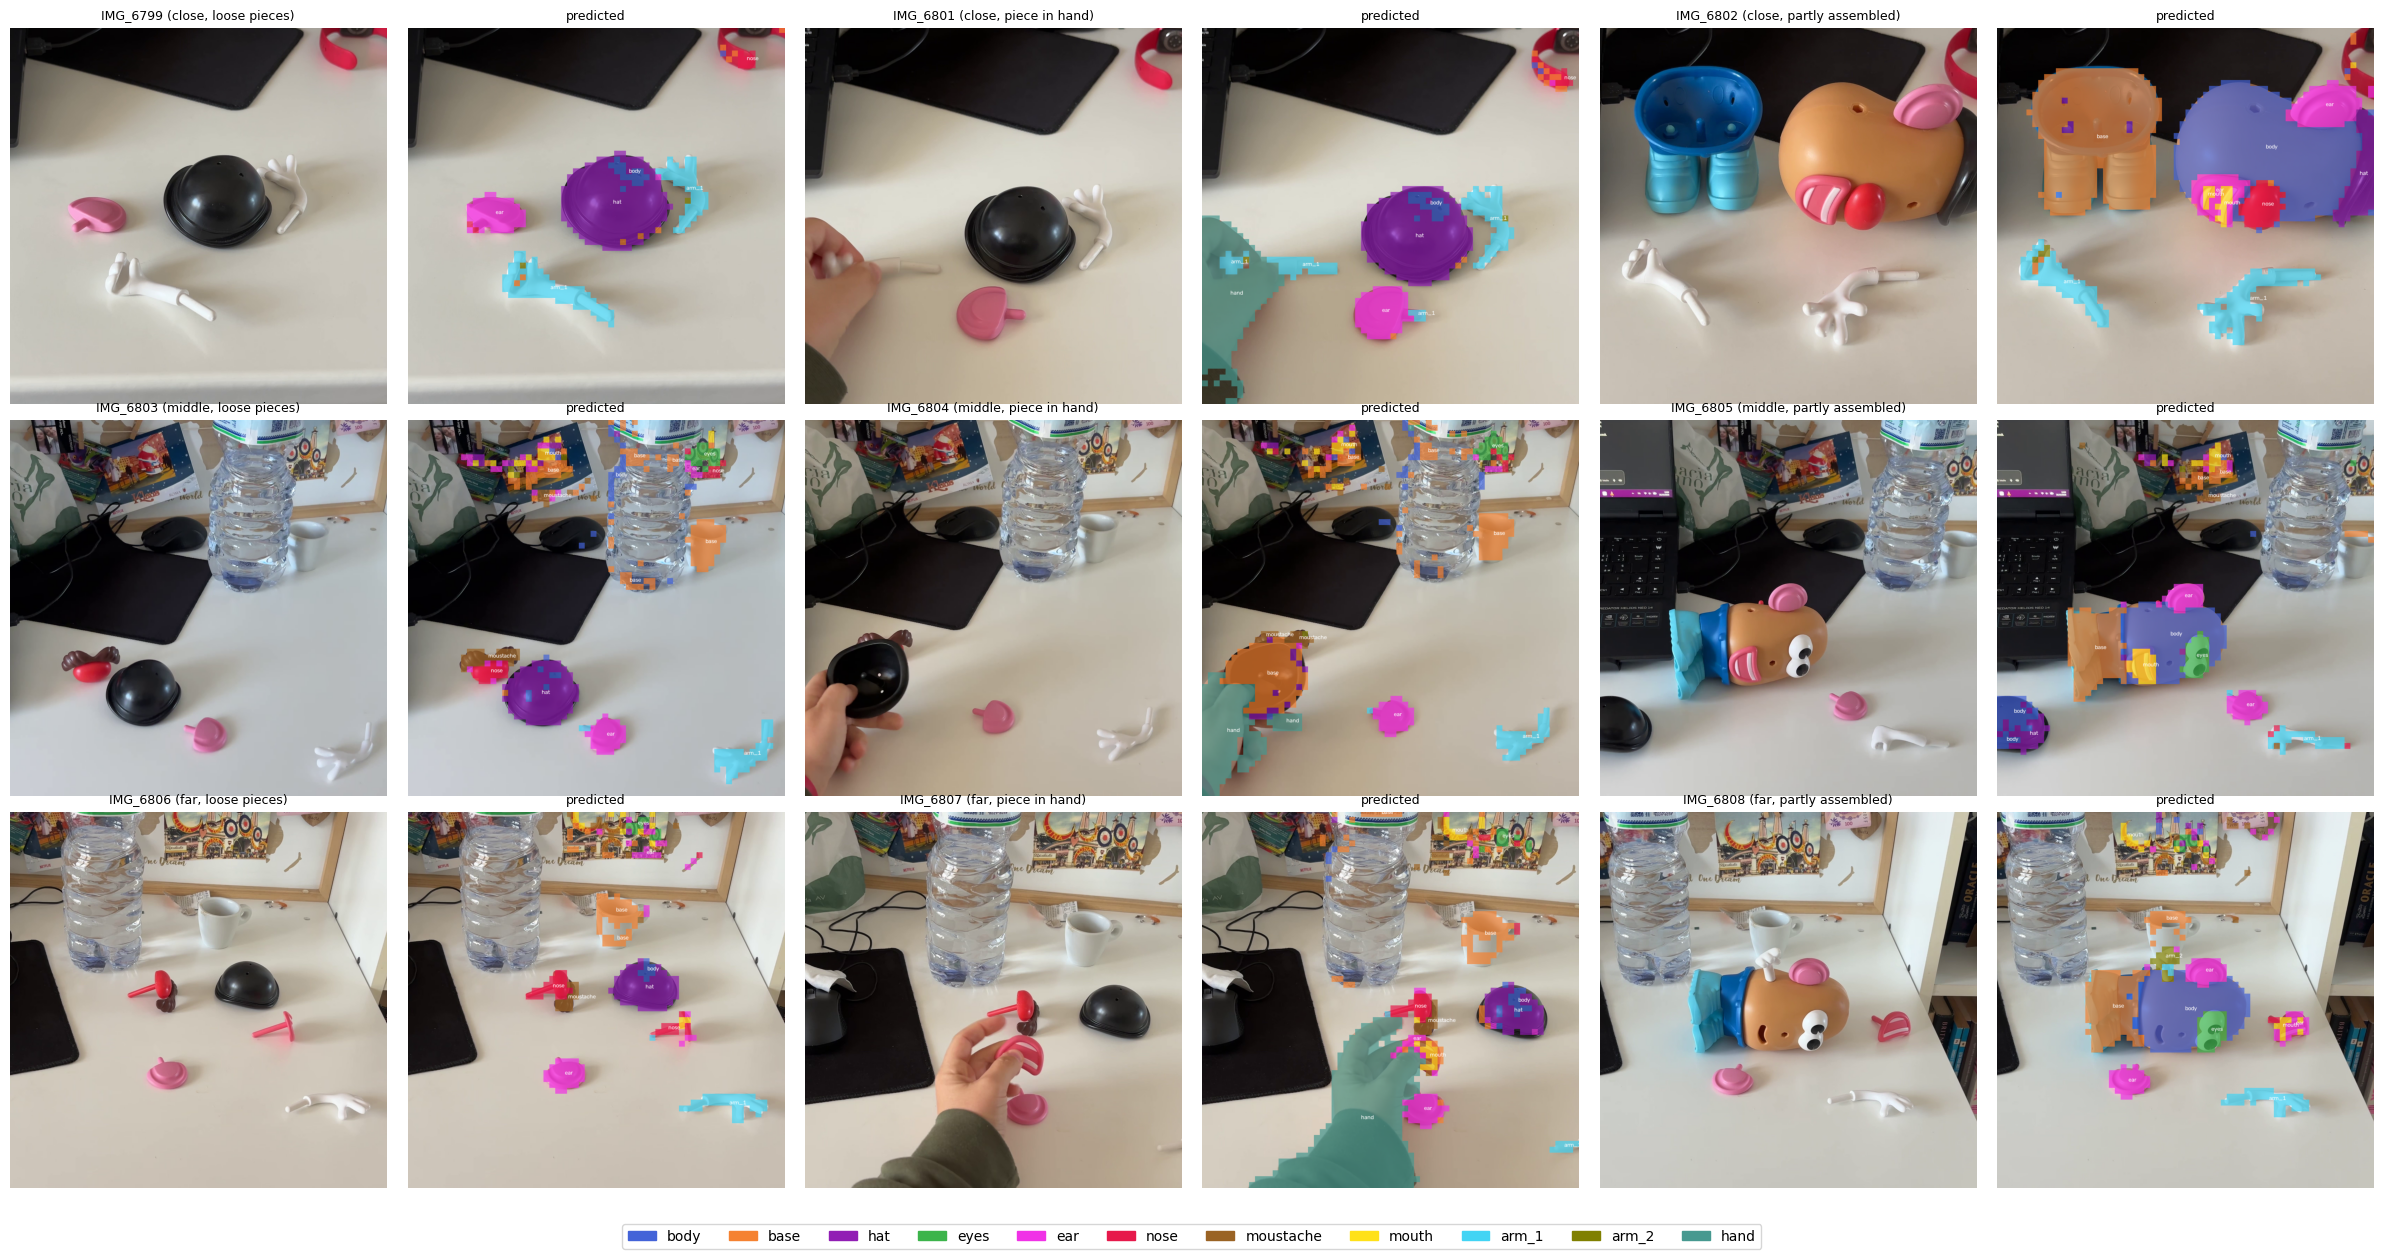

In [4]:
# 3.2 Frames and predictions: one row per distance, frame and prediction for each content
fig, axes = plt.subplots(3, 6, figsize=(24, 12.5))
for row, distance in zip(axes, CLIPS):
    for j, item in enumerate(i for i in FRAMES if i["distance"] == distance):
        image = np.asarray(item["image"])
        row[2 * j].imshow(image)
        row[2 * j].set_title(f"{item['clip']} ({distance}, {item['content']})", fontsize=9)
        row[2 * j + 1].imshow(render_overlay(image, item["labels"], MIN_BLOB_PATCHES))
        row[2 * j + 1].set_title("predicted", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
legend = [mpatches.Patch(color=CLASS_COLORS[name], label=name) for name in CLASS_NAMES if name != BACKGROUND_LABEL]
fig.legend(handles=legend, loc="lower center", ncol=11)
plt.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(OUTPUT_DIR / "iphone_scene_predictions.png", dpi=90, bbox_inches="tight")
plt.show()

Observation 3.2: The hat, the ear, the nose and the moustache on the table take their class at all three distances. The figure lying on its side is labelled body and base in the three series, and at the far distance its eyes and ear are found too. The mouth gets mouth patches, but close up many more of its patches are labelled ear. A glossy reflection on the hat gets a few body patches. The operator's hands and forearms are labelled hand, which is the intended simplification.

The arms of the figure are the main problem. Both arms are labelled arm_1, and arm_2 has at most 15 patches in a frame. A piece held in the hand breaks up: the mouth in IMG_6807 becomes a mix of ear, nose and moustache. The hat held upside down (IMG_6804) is labelled base almost entirely, with a few moustache patches at its rim: seen from inside it looks like the cavity of the base, the same confusion between hat and base seen in the test, in the other direction.

Objects never seen are partly taken for pieces, but not the expected ones. The colourful poster becomes a mix of hat, ear, base, eyes and mouth patches in the middle and far series; the white mug is labelled base in three frames (IMG_6803, IMG_6806, IMG_6807); a red strap is labelled nose (IMG_6799, IMG_6801); the cap and the label of the bottle get a few base and body patches. The dark objects, mouse pad, keyboard and mouse, stay mostly background.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 3:

Phase 1 test (phase_1_test.ipynb), Sections 6 and 7: the saved prototypes loaded and checked, and the same classification.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 4 - Conclusions

Perception of Phase 1, unchanged, carries over in part to a phone camera, a new room and a pose never seen. The pieces at rest on the table, the figure lying on its side and the operator's hands are mostly recognized at all three distances. The new errors come from the background: colourful or bright objects, such as the poster, the mug and a red strap, are partly taken for pieces, because there is no "unknown" answer and all background prototypes come from the laboratory; dark objects are not.

The errors of the pieces are those known from Phase 1, and here they are more visible. The two arms of the figure are not told apart. The mouth is partly taken for ear. A piece held in the hand breaks up into neighbouring classes or into base, as the hat held upside down.

Of the expectations written before the run, two hold (objects never seen taken for pieces, bare hands recognized as hand), one holds only in part (the dark objects stay background), and two do not (the far series is not clearly better, since distance and clutter change together; the lying figure is not recognized worse).

For Phase 2 this supports recording on a neutral background, which removes most errors due to the scene. It also confirms that the pick is the weak moment of perception: the identity of a piece in the hand cannot be read from a single frame, and has to come from what was seen before the pick, which Phase 2 must keep over time. The identity of the two arms remains the main open problem.

These are nine frames, not annotated: they describe, they do not measure.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 4: none. The known limits are those of the Phase 1 test (phase_1_test.ipynb, Section 9).

------------------------------------------------------------------------------------------------------------------------------------------

## Section 5 - Arm mounted on the wrong side (quick check on single photos)

In the test of Phase 1 the arms were labelled correctly only once mounted. This may come from their shape or from the side of the body where they are. If it comes from the side, an arm mounted on the wrong side would take the class of that side, and the error would be invisible to the later phases.

The photos show the figure upright with one arm mounted on the wrong side. Expectations, written before the run. If the side decides, arm_1 mounted on the image left is labelled arm_2, and arm_2 mounted on the image right is labelled arm_1. If the shape decides, each arm keeps its class. Only two outcomes are informative: arm_2 labelled arm_2 on the wrong side means that the shape is enough for it; arm_1 labelled arm_2 on the wrong side means that the side decides. arm_2 labelled arm_1 says nothing new, since arm_2 is taken for arm_1 in most poses.

These are phone photos, not video frames, and the figure is much larger than in use: they give a first answer, not a measure.

IMG_6809.jpeg (arm_2 mounted on the image right (wrong side)): arm_1 39 patches, arm_2 5 patches
IMG_6811.jpeg (arm_1 on the image left and arm_2 on the image right (both on the wrong side)): arm_1 65 patches, arm_2 40 patches


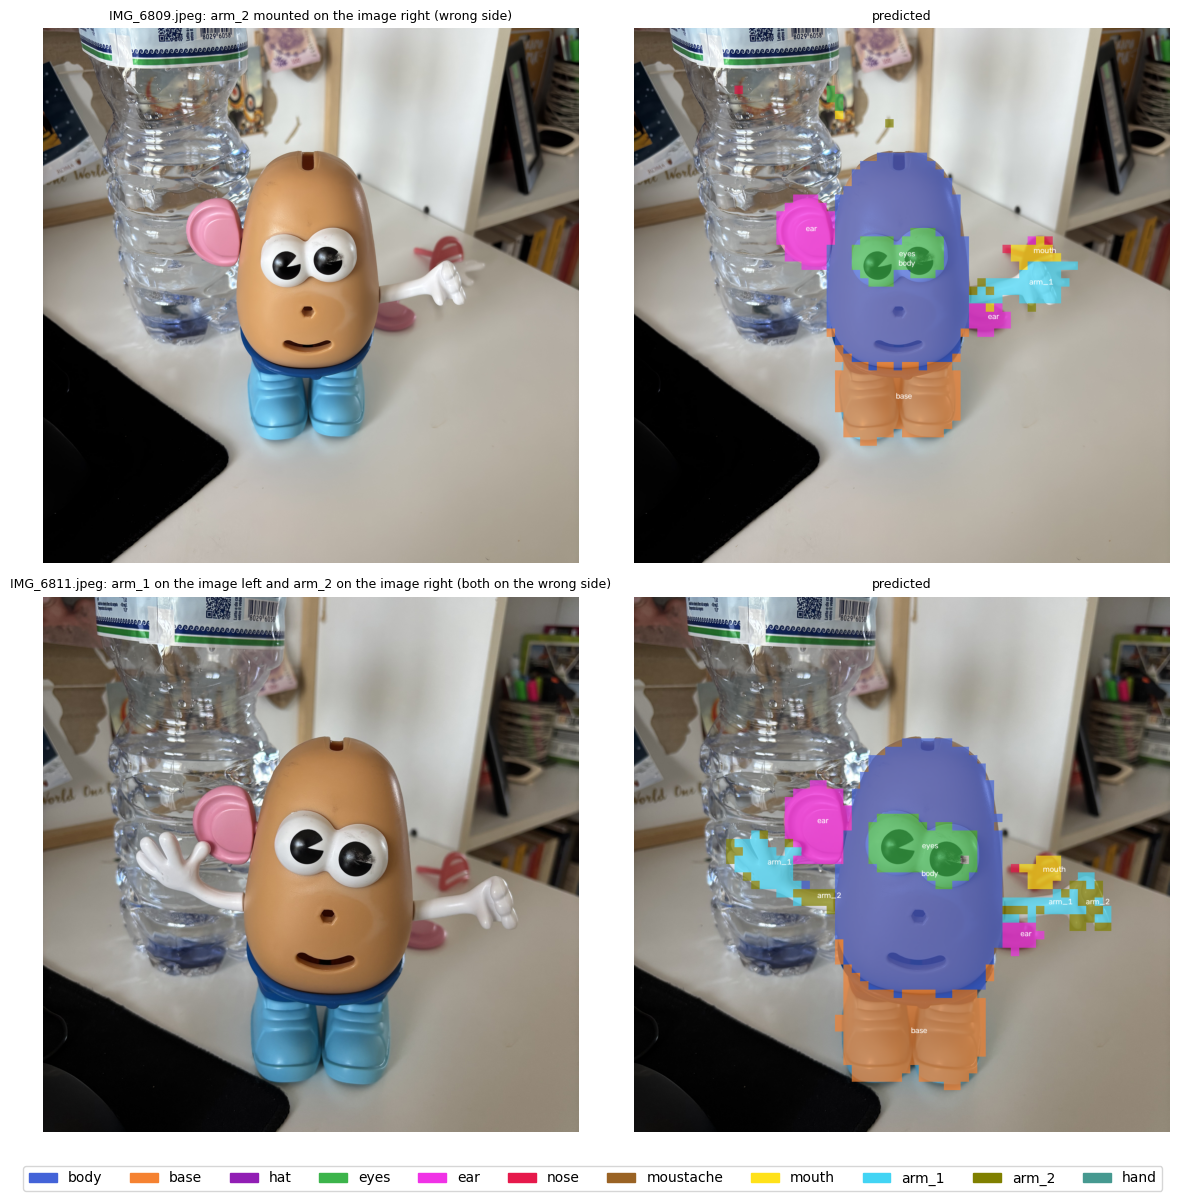

In [7]:
# 5.1 Photos with an arm mounted on the wrong side: labels and arm patches
from PIL import ImageOps

PHOTOS = {"IMG_6809.jpeg": "arm_2 mounted on the image right (wrong side)",
          "IMG_6811.jpeg": "arm_1 on the image left and arm_2 on the image right (both on the wrong side)"}
PHOTOS_DIR = PROJECT_ROOT / "data" / "raw_videos" / "iphone_scene"

ARM_IDS = {name: CLASS_NAMES.index(name) for name in ["arm_1", "arm_2"]}
fig, axes = plt.subplots(len(PHOTOS), 2, figsize=(12, 6 * len(PHOTOS)), squeeze=False)
for row, (name, description) in zip(axes, PHOTOS.items()):
    photo = ImageOps.exif_transpose(Image.open(PHOTOS_DIR / name)).convert("RGB")
    w, h = photo.size
    side = min(w, h)
    photo = photo.crop(((w - side) // 2, (h - side) // 2, (w - side) // 2 + side, (h - side) // 2 + side))
    photo = photo.resize((SIZE, SIZE), Image.Resampling.LANCZOS)
    features, _ = extractor.extract(photo)
    labels = assign_labels(class_similarities_gpu(features, *PROTOTYPES_GPU), MARGIN)
    counts = {arm: int((labels == i).sum()) for arm, i in ARM_IDS.items()}
    print(f"{name} ({description}): arm_1 {counts['arm_1']} patches, arm_2 {counts['arm_2']} patches")
    image = np.asarray(photo)
    row[0].imshow(image)
    row[0].set_title(f"{name}: {description}", fontsize=9)
    row[1].imshow(render_overlay(image, labels, MIN_BLOB_PATCHES))
    row[1].set_title("predicted", fontsize=9)
    for ax in row:
        ax.axis("off")
fig.legend(handles=legend, loc="lower center", ncol=11)
plt.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(OUTPUT_DIR / "arm_wrong_side.png", dpi=90, bbox_inches="tight")
plt.show()

Observation 5.1: The decisive case is in IMG_6811: arm_1, with its open hand, mounted on the image left, the place of arm_2, is labelled arm_1. The side of the body therefore does not decide the class of a mounted arm in these photos; its shape does, and an arm mounted on the wrong side is not hidden by its position.

arm_2 is recognized only by its closed hand, and not always. In IMG_6811, mounted on the image right, its closed hand is labelled arm_2 and the rest of the arm arm_1 (40 and 65 patches over both arms). In IMG_6809, in the same place, it is labelled almost entirely arm_1 (39 patches against 5). The smooth white part of the two arms is the same in both pieces, and only the hand tells them apart.

A decision taken on the whole object from its most distinctive patches would label the two arms of IMG_6811 correctly, and would find the swap; in IMG_6809 the evidence is too weak, and the identity would have to come from earlier frames. These are two photos with the figure much larger than in use: they give a first answer, not a measure.

## Section 6 - The arms over time (three clips, exploratory)

Three clips show only the arms, on a white table and from above: arm_2 alone and then picked (IMG_6812), arm_1 alone, picked, turned and put back (IMG_6813), and both arms together, then picked (IMG_6814). Perception runs on every frame, and the patches labelled arm_1 and arm_2 are counted over time.

The question is whether arm_2, seen from many angles, shows arm_2 patches in at least part of the frames; if so, its identity could be recovered by gathering evidence over time, which is a task for Phase 2. Expectations, written before the run: arm_1 is labelled arm_1 in most frames; arm_2 is labelled mostly arm_1, with arm_2 patches on its closed hand in some frames, more when the hand is seen from above than from the side. The arms are much larger than in use, so the answer may not hold at working distance.

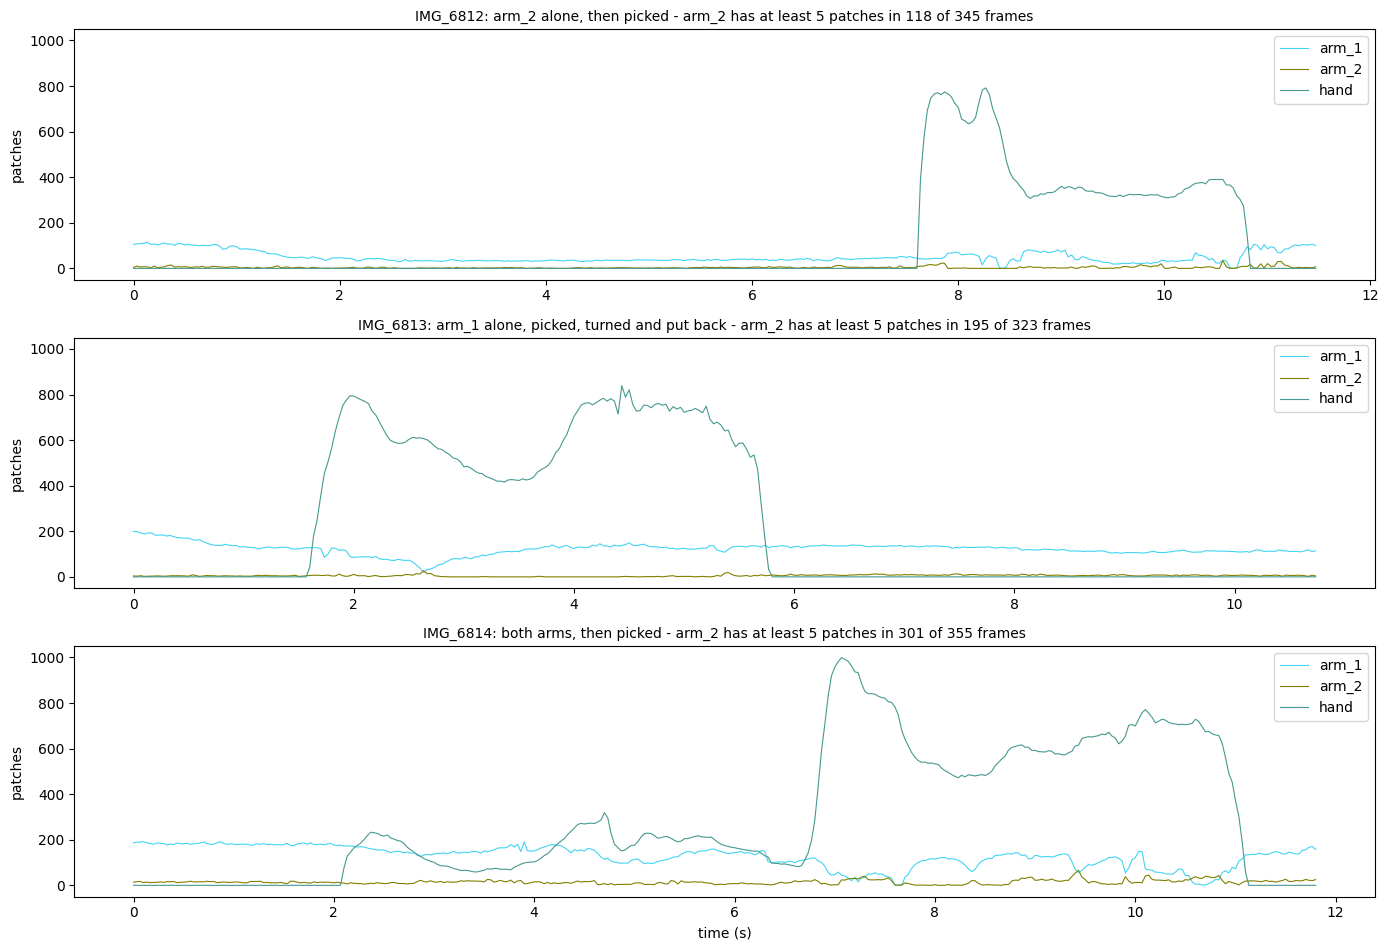

In [8]:
# 6.1 Perception on every frame of the three arm clips: arm_1, arm_2 and hand patches over time
ARM_CLIPS = {"IMG_6812": "arm_2 alone, then picked",
             "IMG_6813": "arm_1 alone, picked, turned and put back",
             "IMG_6814": "both arms, then picked"}
ids = {name: CLASS_NAMES.index(name) for name in ["arm_1", "arm_2", "hand"]}

fig, axes = plt.subplots(len(ARM_CLIPS), 1, figsize=(14, 3.2 * len(ARM_CLIPS)), sharey=True)
for ax, (clip, description) in zip(axes, ARM_CLIPS.items()):
    cap = cv2.VideoCapture(str(CLIPS_DIR / f"{clip}.MOV"))
    fps = cap.get(cv2.CAP_PROP_FPS)
    series = {name: [] for name in ids}
    while True:
        ok, frame_bgr = cap.read()
        if not ok:
            break
        h, w = frame_bgr.shape[:2]
        side = min(h, w)
        square = frame_bgr[(h - side) // 2:(h - side) // 2 + side, (w - side) // 2:(w - side) // 2 + side]
        image = Image.fromarray(cv2.cvtColor(square, cv2.COLOR_BGR2RGB)).resize((SIZE, SIZE), Image.Resampling.LANCZOS)
        features, _ = extractor.extract(image)
        labels = assign_labels(class_similarities_gpu(features, *PROTOTYPES_GPU), MARGIN)
        for name, i in ids.items():
            series[name].append(int((labels == i).sum()))
    cap.release()
    times = np.arange(len(series["arm_1"])) / fps
    for name in ids:
        ax.plot(times, series[name], linewidth=0.8, color=CLASS_COLORS[name], label=name)
    arm_2 = np.array(series["arm_2"])
    ax.set_title(f"{clip}: {description} - arm_2 has at least {MIN_BLOB_PATCHES} patches in "
                 f"{(arm_2 >= MIN_BLOB_PATCHES).sum()} of {len(arm_2)} frames", fontsize=10)
    ax.set_ylabel("patches")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("time (s)")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "arms_over_time.png", dpi=100, bbox_inches="tight")
plt.show()